# Local-kaon-fraction solver comparison

This notebook compares the established energy-conserving solver with the new absolute-`nK` solver at `nB_N = 3*n0`, `aQstar = 0.3`, `T_N = 10 MeV`, and `B^(1/4) = 180 MeV`.

The cubic source from the old solver is multiplied by its fixed downstream baryon density before comparison, so both reaction curves are density rates in the same natural-unit convention.

In [2]:
import importlib
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)

# Physical inputs
n0 = 0.16 * const.MeV_fm**3
T_N = 10.0
nB_N = 3.0 * n0
B14 = 180.0
aQstar = 0.3
ms = 0.0
NM_type = "PNM"
param = para.paraQMCRMF3

# Shared solver controls
TAIL_EPS = 1.0e-5
N_MESH = 40
TOL_BVP = 1.0e-4
MAX_NODES = 5000
JB_BOUNDS = (1.0e-4, 5.0)

print(f"T_N = {T_N:g} MeV")
print(f"nB_N = {nB_N / n0:g} n0")
print(f"aQstar = {aQstar:g}")
print(f"B^(1/4) = {B14:g} MeV")

T_N = 10 MeV
nB_N = 3 n0
aQstar = 0.3
B^(1/4) = 180 MeV


## Solve both formulations

The old solver evolves its reference-normalized composition and uses the cubic rate. The new solver evolves the absolute kaon density, reconstructs the local fraction, and evaluates the exact chemical-potential rate.

In [3]:
shared_solver_kwargs = dict(
    T=T_N,
    nB_N=nB_N,
    B_one_forth=B14,
    aQstar=aQstar,
    ms=ms,
    param=param,
    NM_type=NM_type,
    tail_eps=TAIL_EPS,
    n_mesh=N_MESH,
    tol_bvp=TOL_BVP,
    max_nodes=MAX_NODES,
    jB_bounds=JB_BOUNDS,
    return_profile=True,
    verb=False,
)

old_result = phase_velocity.solve_front_energy_conserving(
    **shared_solver_kwargs,
    jB_guess=0.5,
    TQ_guess=30.0,
)
new_result = phase_velocity.solve_front_energy_conserving_nK(
    **shared_solver_kwargs,
    jB_guess=0.5,
)

for label, result in (("Old cubic solver", old_result), ("New exact nK solver", new_result)):
    if not bool(result.get("success")):
        raise RuntimeError(f"{label} failed: {result.get('message')}")

solver_summary = pd.DataFrame([
    {
        "solver": "old cubic",
        "jB": float(old_result["jB"]),
        "u_N_m_per_s": float(old_result["u_N"]) * const.m_per_sec,
        "T_Q_MeV": float(old_result["T_Q"]),
        "aQstar_derived": float(old_result["a"][0]),
        "tail_residual_norm": float(old_result["tail_residual_norm"]),
        "kaon_equation_residual_norm": float(old_result["kaon_equation_residual_norm"]),
    },
    {
        "solver": "new exact nK",
        "jB": float(new_result["jB"]),
        "u_N_m_per_s": float(new_result["u_N"]) * const.m_per_sec,
        "T_Q_MeV": float(new_result["T_Q"]),
        "aQstar_derived": float(new_result["aQstar_derived"]),
        "tail_residual_norm": float(new_result["tail_residual_norm"]),
        "kaon_equation_residual_norm": float(new_result["kaon_equation_residual_norm"]),
    },
])
display(solver_summary)

,solver,jB,u_N_m_per_s,T_Q_MeV,aQstar_derived,tail_residual_norm,kaon_equation_residual_norm
0,old cubic,0.502003,40.806261,31.82403,0.3,7.479085e-05,4.472482e-18
1,new exact nK,0.505056,41.054391,31.82403,0.3,9.452888e-19,1.897151e-07


## Derived comparison arrays

For `ms = 0`, the old composition coordinate implies `nK = nB_Q*a`. The old cubic reaction is converted to a density rate as `nB_Q*R_cubic`, matching the dimensions of the new exact rate.

In [4]:
old_x_nm = np.asarray(old_result["x"], dtype=float) * const.MeV_fm / 1.0e6
new_x_nm = np.asarray(new_result["x"], dtype=float) * const.MeV_fm / 1.0e6

old_a = np.asarray(old_result["a"], dtype=float)
new_a = np.asarray(new_result["a"], dtype=float)
old_nB = np.asarray(old_result["nB"], dtype=float)
new_nB = np.asarray(new_result["nB"], dtype=float)
old_nK = float(old_result["nK_Q"]) + float(old_result["nB_Q"]) * old_a
new_nK = np.asarray(new_result["nK"], dtype=float)

old_u_m_per_s = np.asarray(old_result["u"], dtype=float) * const.m_per_sec
new_u_m_per_s = np.asarray(new_result["u"], dtype=float) * const.m_per_sec
old_T = np.asarray(old_result["T_profile"], dtype=float)
new_T = np.asarray(new_result["T_profile"], dtype=float)
old_muK = np.asarray(old_result["muK"], dtype=float)
new_muK = np.asarray(new_result["muK"], dtype=float)
old_muB = np.asarray(old_result["muB"], dtype=float)
new_muB = np.asarray(new_result["muB"], dtype=float)

old_cubic_density_rate = float(old_result["nB_Q"]) * np.asarray(old_result["R_kaon_profile"], dtype=float)
new_exact_density_rate = np.asarray(new_result["Gamma_K_profile"], dtype=float)

rate_comparison = pd.DataFrame([
    {
        "quantity": "maximum density rate",
        "old_cubic": float(np.max(old_cubic_density_rate)),
        "new_exact": float(np.max(new_exact_density_rate)),
        "relative_change": float(np.max(new_exact_density_rate) / np.max(old_cubic_density_rate) - 1.0),
    },
    {
        "quantity": "front velocity",
        "old_cubic": float(old_result["u_N"]) * const.m_per_sec,
        "new_exact": float(new_result["u_N"]) * const.m_per_sec,
        "relative_change": float(new_result["u_N"] / old_result["u_N"] - 1.0),
    },
])
display(rate_comparison)

,quantity,old_cubic,new_exact,relative_change
0,maximum density rate,0.000001,0.000001,0.043350
1,front velocity,40.806261,41.054391,0.006081


## Spatial profile comparison

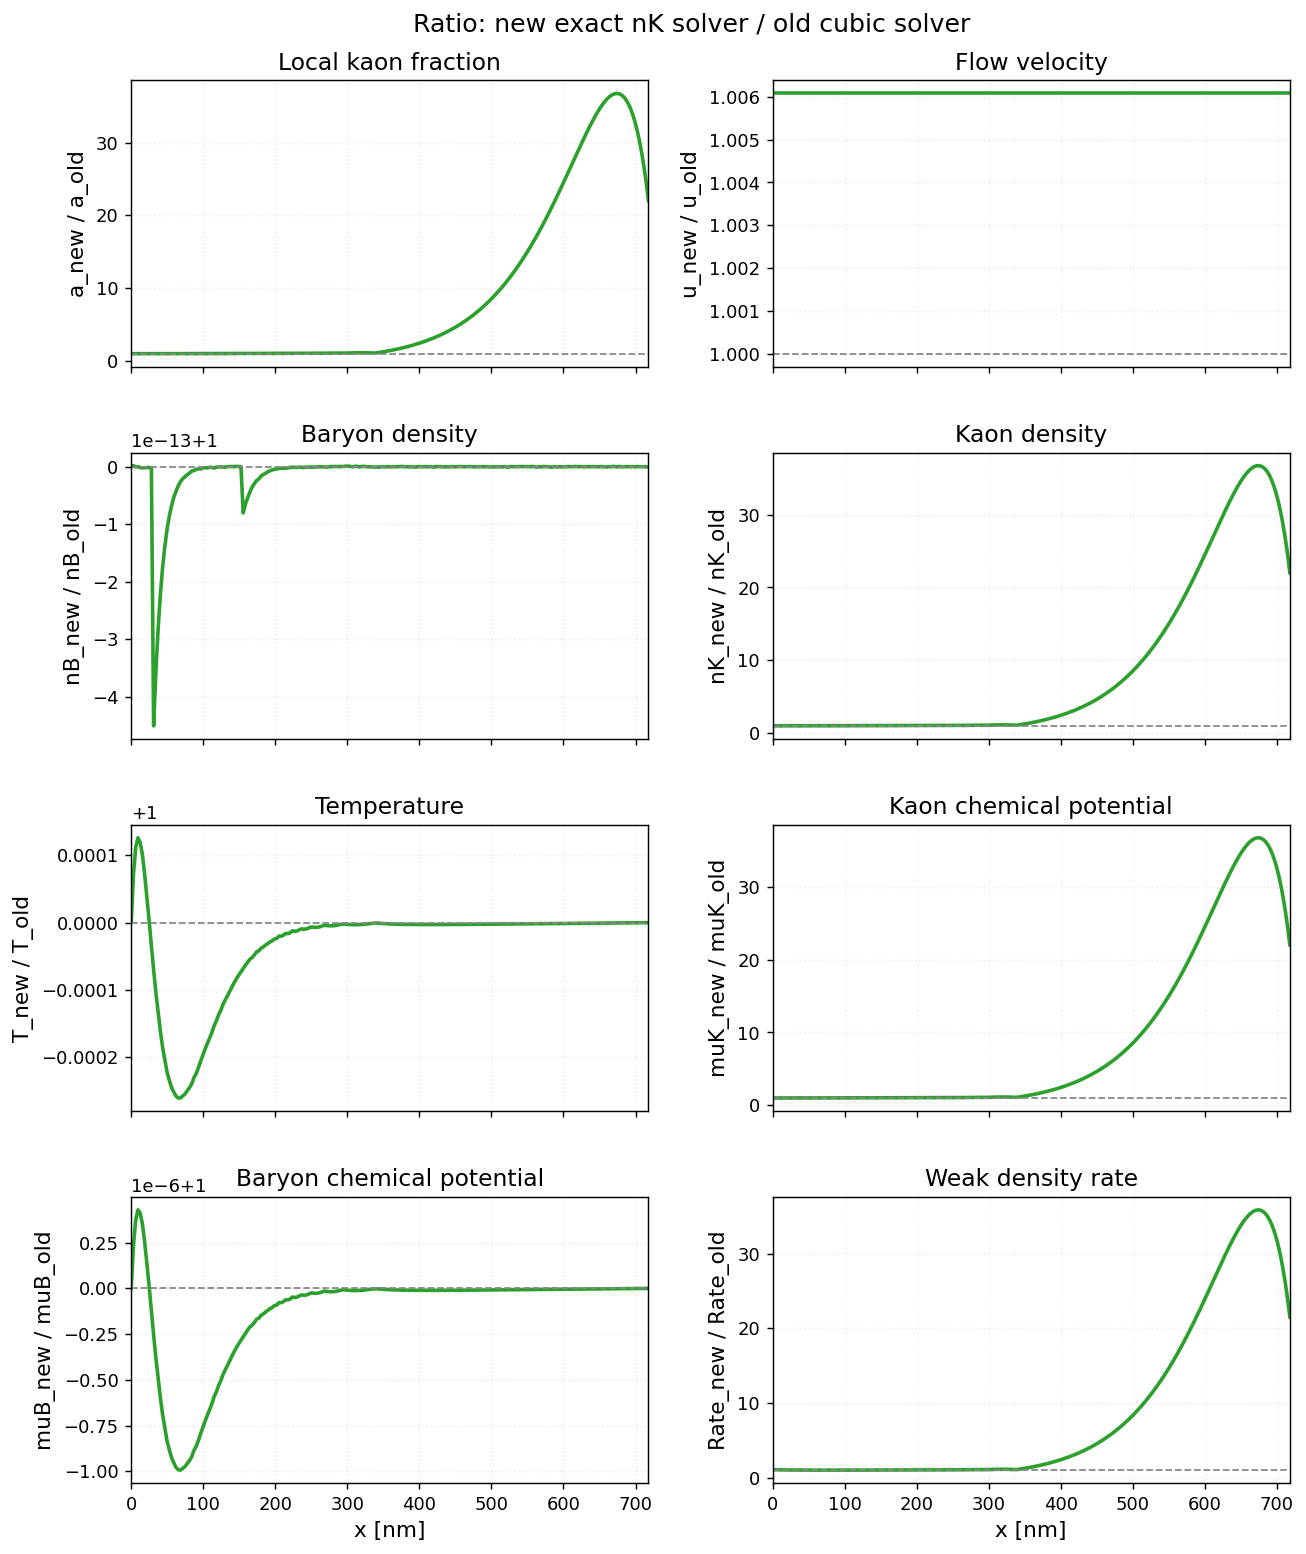

In [8]:
# Tunable plotting parameters
FIGURE_SIZE = (11.5, 13.0)
FIGURE_DPI = 130
TITLE_FONT_SIZE = 13
AXIS_LABEL_FONT_SIZE = 12
TICK_LABEL_FONT_SIZE = 10
LINE_WIDTH = 2.0
RATIO_COLOR = "#2ca02c"
RATIO_LINE_STYLE = "-"
REFERENCE_COLOR = "#888888"
REFERENCE_LINE_STYLE = "--"
REFERENCE_LINE_WIDTH = 1.0
GRID_ALPHA = 0.25
GRID_LINE_STYLE = ":"
X_MIN_NM = 0.0
X_MAX_NM = min(float(old_x_nm[-1]), float(new_x_nm[-1]))
RATE_RATIO_Y_SCALE = "linear"
ZERO_THRESHOLD = 1.0e-30
SUBPLOT_HSPACE = 0.30
SUBPLOT_WSPACE = 0.24

from scipy.interpolate import interp1d

x_ref = old_x_nm[(old_x_nm >= X_MIN_NM) & (old_x_nm <= X_MAX_NM)]

def _ratio_on_ref(old_x, old_y, new_x, new_y):
    old_y = np.asarray(old_y, dtype=float)
    f_new = interp1d(new_x, new_y, kind="linear", bounds_error=False, fill_value=np.nan)
    mask = (old_x >= X_MIN_NM) & (old_x <= X_MAX_NM)
    denom = old_y[mask]
    numer = f_new(x_ref)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(np.abs(denom) > ZERO_THRESHOLD, numer / denom, np.nan)
    return ratio

profile_panels = [
    (old_a,                  new_a,                  "Local kaon fraction",    "a_new / a_old"),
    (old_u_m_per_s,          new_u_m_per_s,          "Flow velocity",          "u_new / u_old"),
    (old_nB / n0,            new_nB / n0,            "Baryon density",         "nB_new / nB_old"),
    (old_nK / n0,            new_nK / n0,            "Kaon density",           "nK_new / nK_old"),
    (old_T,                  new_T,                  "Temperature",            "T_new / T_old"),
    (old_muK,                new_muK,                "Kaon chemical potential","muK_new / muK_old"),
    (old_muB,                new_muB,                "Baryon chemical potential","muB_new / muB_old"),
    (old_cubic_density_rate, new_exact_density_rate, "Weak density rate",      "Rate_new / Rate_old"),
]

fig, axes = plt.subplots(4, 2, figsize=FIGURE_SIZE, dpi=FIGURE_DPI, sharex=True)
axes = axes.ravel()
for index, (old_values, new_values, title, ylabel) in enumerate(profile_panels):
    ratio = _ratio_on_ref(old_x_nm, old_values, new_x_nm, new_values)
    axes[index].plot(x_ref, ratio, color=RATIO_COLOR, linestyle=RATIO_LINE_STYLE, linewidth=LINE_WIDTH)
    axes[index].axhline(1.0, color=REFERENCE_COLOR, linestyle=REFERENCE_LINE_STYLE,
                        linewidth=REFERENCE_LINE_WIDTH)
    axes[index].set_title(title, fontsize=TITLE_FONT_SIZE)
    axes[index].set_ylabel(ylabel, fontsize=AXIS_LABEL_FONT_SIZE)
    axes[index].set_xlim(X_MIN_NM, X_MAX_NM)
    axes[index].tick_params(labelsize=TICK_LABEL_FONT_SIZE)
    axes[index].grid(alpha=GRID_ALPHA, linestyle=GRID_LINE_STYLE)

axes[-1].set_yscale(RATE_RATIO_Y_SCALE)
for axis in axes[-2:]:
    axis.set_xlabel("x [nm]", fontsize=AXIS_LABEL_FONT_SIZE)

fig.suptitle("Ratio: new exact nK solver / old cubic solver", fontsize=TITLE_FONT_SIZE + 1, y=0.98)
fig.subplots_adjust(top=0.94, hspace=SUBPLOT_HSPACE, wspace=SUBPLOT_WSPACE)
plt.show()

## Projection onto the `(muK, T)` plane

The dashed black curve is the leading constant-pressure isobar. The colored curves are the old and new numerical profile projections, running from the equilibrated state toward the interface state.

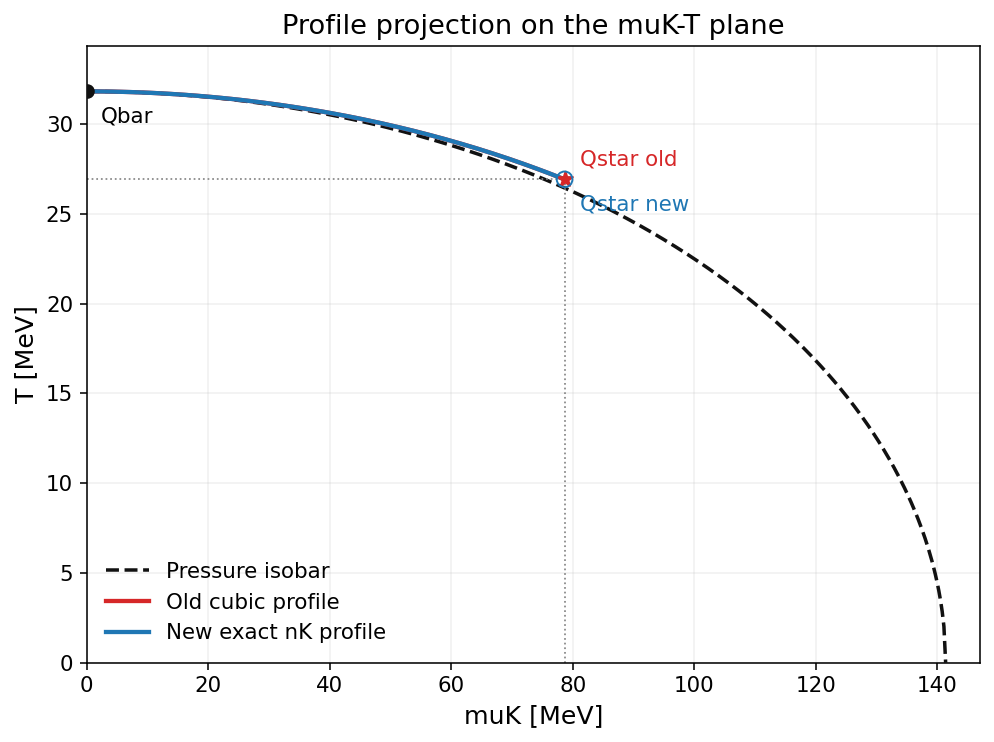

In [6]:
# Tunable plotting parameters
FIGURE_SIZE = (7.2, 5.4)
FIGURE_DPI = 140
TITLE_FONT_SIZE = 14
AXIS_LABEL_FONT_SIZE = 13
TICK_LABEL_FONT_SIZE = 11
LEGEND_FONT_SIZE = 11
LINE_WIDTH = 2.2
ISOBAR_LINE_WIDTH = 1.8
MARKER_SIZE = 65
OLD_COLOR = "#d62728"
NEW_COLOR = "#1f77b4"
ISOBAR_COLOR = "#111111"
OLD_LINE_STYLE = "-"
NEW_LINE_STYLE = "-"
ISOBAR_LINE_STYLE = "--"
GUIDE_COLOR = "#888888"
GUIDE_LINE_STYLE = ":"
GUIDE_LINE_WIDTH = 0.9
GRID_ALPHA = 0.18
ANNOTATION_FONT_SIZE = 11
MU_K_AXIS_PADDING = 1.04
T_AXIS_PADDING = 1.08
ISOBAR_POINT_COUNT = 500
LEGEND_LOCATION = "lower left"

T_Q_ISOBAR = 0.5 * (float(old_result["T_Q"]) + float(new_result["T_Q"]))
MU_K_ISOBAR_MAX = np.sqrt(2.0) * np.pi * T_Q_ISOBAR
muK_isobar = np.linspace(0.0, MU_K_ISOBAR_MAX, ISOBAR_POINT_COUNT)
T_isobar = np.sqrt(np.maximum(T_Q_ISOBAR**2 - muK_isobar**2 / (2.0 * np.pi**2), 0.0))

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
ax.plot(muK_isobar, T_isobar, color=ISOBAR_COLOR, linestyle=ISOBAR_LINE_STYLE, linewidth=ISOBAR_LINE_WIDTH, label="Pressure isobar")
ax.plot(old_muK, old_T, color=OLD_COLOR, linestyle=OLD_LINE_STYLE, linewidth=LINE_WIDTH, label="Old cubic profile")
ax.plot(new_muK, new_T, color=NEW_COLOR, linestyle=NEW_LINE_STYLE, linewidth=LINE_WIDTH, label="New exact nK profile")

ax.scatter([old_muK[0]], [old_T[0]], color=OLD_COLOR, marker="*", s=MARKER_SIZE, zorder=5)
ax.scatter([new_muK[0]], [new_T[0]], color=NEW_COLOR, marker="o", s=MARKER_SIZE, facecolors="none", zorder=5)
ax.scatter([0.0], [T_Q_ISOBAR], color=ISOBAR_COLOR, marker="o", s=0.65 * MARKER_SIZE, zorder=5)

ax.plot([old_muK[0], old_muK[0]], [0.0, old_T[0]], color=GUIDE_COLOR, linestyle=GUIDE_LINE_STYLE, linewidth=GUIDE_LINE_WIDTH)
ax.plot([0.0, old_muK[0]], [old_T[0], old_T[0]], color=GUIDE_COLOR, linestyle=GUIDE_LINE_STYLE, linewidth=GUIDE_LINE_WIDTH)

ax.annotate("Qbar", (0.0, T_Q_ISOBAR), xytext=(7, -16), textcoords="offset points", fontsize=ANNOTATION_FONT_SIZE)
ax.annotate("Qstar old", (old_muK[0], old_T[0]), xytext=(8, 7), textcoords="offset points", color=OLD_COLOR, fontsize=ANNOTATION_FONT_SIZE)
ax.annotate("Qstar new", (new_muK[0], new_T[0]), xytext=(8, -16), textcoords="offset points", color=NEW_COLOR, fontsize=ANNOTATION_FONT_SIZE)

ax.set_title("Profile projection on the muK-T plane", fontsize=TITLE_FONT_SIZE)
ax.set_xlabel("muK [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel("T [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_xlim(0.0, MU_K_AXIS_PADDING * MU_K_ISOBAR_MAX)
ax.set_ylim(0.0, T_AXIS_PADDING * T_Q_ISOBAR)
ax.tick_params(labelsize=TICK_LABEL_FONT_SIZE)
ax.grid(alpha=GRID_ALPHA)
ax.legend(loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE, frameon=False)
plt.tight_layout()
plt.show()